# 🛒 Análisis de los 25 retailers más grandes de Estados Unidos

Proyecto final del reto de **Data Science** de **Platzi (Data Academy)**.
El objetivo es responder preguntas de negocio sobre las ventas, la cantidad de tiendas y las
categorías de las 25 compañías de retail más grandes de EE. UU., aplicando estadística descriptiva
con **Python** (pandas, NumPy, Matplotlib y Seaborn).

**Autora:** Jeanette Mansilla

**Índice**

| Bloque | Preguntas |
|---|---|
| I. Preguntas del negocio | 1 a 6 |
| II. Preguntas opcionales | 7 a 9 |
| III. Preguntas propias | 10 y 11 |

## 0. Preparación del entorno

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

sns.set_theme(style="whitegrid")
COLOR = "darkorange"

# Los gráficos se guardan en docs/images (el README los muestra).
IMG_DIR = Path("../docs/images") if Path("../docs").exists() else Path("docs/images")
IMG_DIR.mkdir(parents=True, exist_ok=True)


def guardar(nombre, figura=None):
    """Guarda el gráfico actual (o la figura indicada) como PNG en docs/images."""
    destino = IMG_DIR / f"{nombre}.png"
    if figura is None:
        plt.savefig(destino, dpi=120, bbox_inches="tight")
    else:
        figura.savefig(destino, dpi=120, bbox_inches="tight")


def miles(valor, decimales=0):
    """Formato argentino: 46602.4 -> '46.602' (punto para miles, coma para decimales)."""
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

ModuleNotFoundError: No module named 'matplotlib'

## Datos

El dataset `largest_us_retailers.csv` tiene **25 filas** (una por compañía) y 6 columnas:

| Columna | Significado |
|---|---|
| `Company` | Nombre de la compañía |
| `Sales` | Ventas anuales, en millones de USD |
| `Stores` | Cantidad de tiendas físicas |
| `Sales/Avg. Store` | Ventas por tienda promedio, en millones de USD (ya viene calculada) |
| `Store Count Growth` | Crecimiento de la cantidad de tiendas (proporción: 0,05 = 5 %) |
| `Category` | Categoría de la compañía |

> Las ventas están en **millones de USD**. Es el supuesto del enunciado del reto; si se
> consigue la fuente original del dataset conviene confirmarlo.

In [ ]:
RUTA = Path("../data/largest_us_retailers.csv")
if not RUTA.exists():  # por si el notebook se ejecuta desde la raíz del repositorio
    RUTA = Path("data/largest_us_retailers.csv")

datos = pd.read_csv(RUTA)
datos.head()

,Company,Sales,Stores,Sales/Avg. Store,Store Count Growth,Category
0,Walmart US,658119,4574.0,65.649725,0.012843,Supercenters
1,Kroger,115037,3931.0,30.031850,0.053887,Grocery
2,Costco,90048,495.0,187.795620,0.066810,Warehouse Club
3,Home Depot,83976,1965.0,42.735878,0.000000,Home Improvement
4,Walgreen Boots,78924,8002.0,9.810927,-0.010511,Drug Stores


### Calidad de los datos

Antes de analizar conviene mirar los valores nulos:

In [ ]:
print("Filas y columnas:", datos.shape)
datos.isna().sum()

Filas y columnas: (25, 6)


Company               0
Sales                 0
Stores                2
Sales/Avg. Store      2
Store Count Growth    2
Category              1
dtype: int64

- **Amazon** y **Apple incl. Online** no tienen dato de `Stores`, `Sales/Avg. Store` ni
  `Store Count Growth`. Más adelante (pregunta 9) usamos esa ausencia para identificarlas como
  compañías sin tiendas físicas informadas.
- **Apple incl. Online** tampoco tiene `Category`.

## Exploración inicial de las ventas

In [ ]:
datos_sorted = datos.sort_values("Sales", ascending=False)
datos_sorted.describe().round(2)

,Sales,Stores,Sales/Avg. Store,Store Count Growth
count,25.00,23.00,23.00,23.00
mean,71063.08,3466.57,36.87,0.04
std,125405.73,4038.71,40.63,0.07
min,16592.00,231.00,1.56,-0.06
25%,24402.00,1029.00,11.26,-0.00
50%,34980.00,1828.00,26.00,0.02
75%,71687.00,4242.00,41.36,0.08
max,658119.00,14250.00,187.80,0.26


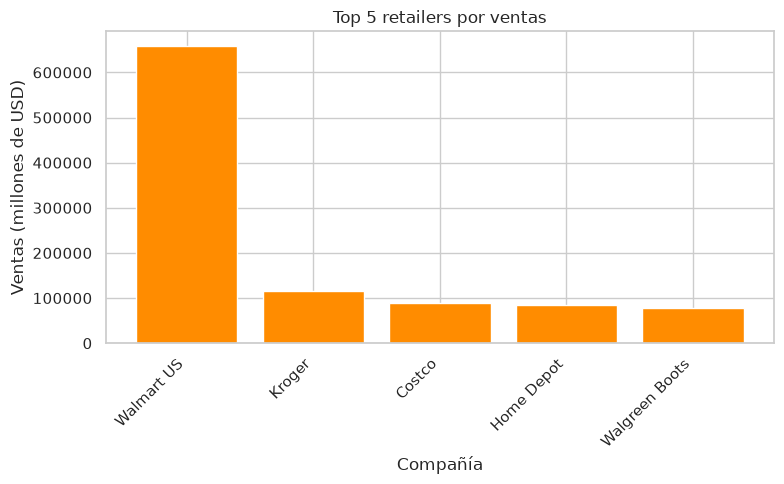

In [ ]:
top5 = datos_sorted.head(5)

plt.figure(figsize=(8, 5))
plt.bar(top5["Company"], top5["Sales"], color=COLOR)
plt.title("Top 5 retailers por ventas")
plt.xlabel("Compañía")
plt.ylabel("Ventas (millones de USD)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
guardar("01_top5_ventas")
plt.show()

Walmart US vende casi 6 veces más que la segunda (Kroger). Esa diferencia condiciona todo el
análisis: por eso en varias preguntas se usa la **mediana** o se excluye a Walmart US.

## I. Preguntas del negocio

### 1. ¿Cuál es el promedio de ventas sin contar a la compañía dominante?

**Respuesta:** sin contar a la compañía dominante (**Walmart US**), el promedio de ventas de las
otras 24 compañías es de **USD 46.602 millones**. Con Walmart US incluida el promedio sube a
71.063: una sola empresa lo infla un 52 %.

In [ ]:
sin_dominante = datos[datos["Company"] != "Walmart US"]

promedio_sin_dominante = sin_dominante["Sales"].mean()
print(f"Promedio de ventas sin Walmart US: {miles(promedio_sin_dominante)} millones de USD")
print(f"Promedio de ventas con Walmart US: {miles(datos['Sales'].mean())} millones de USD")

sin_dominante["Sales"].describe().round(2)

Promedio de ventas sin Walmart US: 46.602 millones de USD
Promedio de ventas con Walmart US: 71.063 millones de USD


count        24.00
mean      46602.42
std       28317.98
min       16592.00
25%       23860.00
50%       34694.00
75%       71327.75
max      115037.00
Name: Sales, dtype: float64

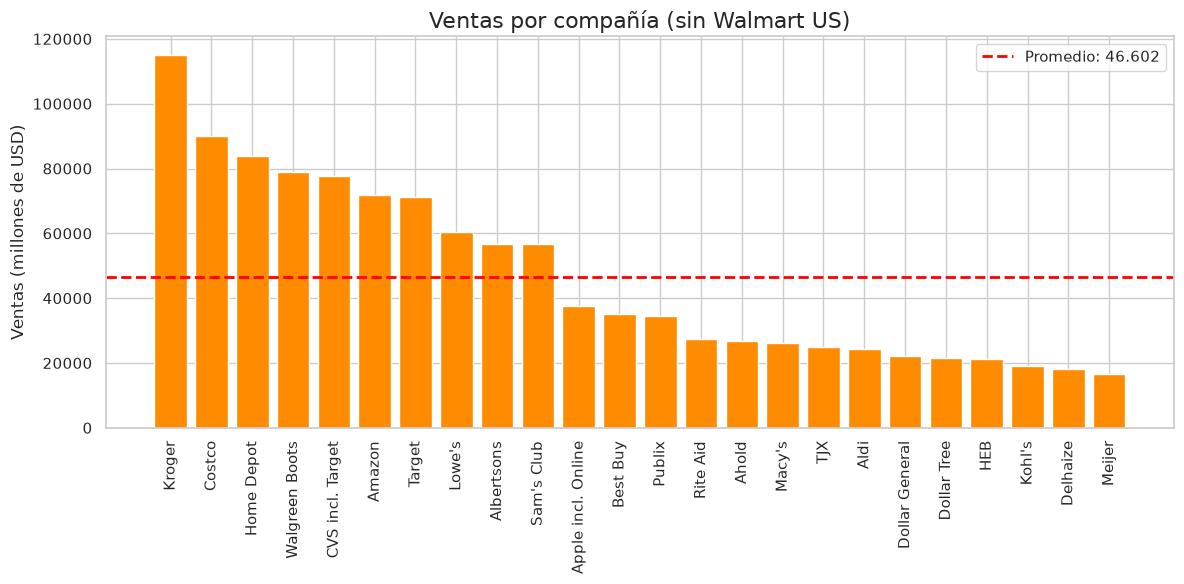

In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(sin_dominante["Company"], sin_dominante["Sales"], color=COLOR)
plt.axhline(
    promedio_sin_dominante,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Promedio: {miles(promedio_sin_dominante)}",
)
plt.title("Ventas por compañía (sin Walmart US)", size=16)
plt.ylabel("Ventas (millones de USD)")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
guardar("02_ventas_sin_walmart")
plt.show()

### 2. ¿Cuánto dinero en ventas generó la mayoría de las compañías?

**Respuesta:** la **mediana** de ventas es de **USD 34.980 millones** anuales (es lo que vende
Best Buy, la compañía que queda justo en el medio del ranking).

**¿Por qué la mediana y no el promedio?** Porque los datos están sesgados: Walmart US eleva el
promedio a 71.063, un valor que ninguna compañía "típica" alcanza. La mediana casi no se mueve si
se excluye a Walmart (34.694), así que representa mejor a la mayoría.

In [ ]:
mediana_ventas = datos["Sales"].median()
promedio_ventas = datos["Sales"].mean()
mediana_sin_walmart = sin_dominante["Sales"].median()

print(f"Mediana de ventas (25 compañías): {miles(mediana_ventas)}")
print(f"Promedio de ventas (25 compañías): {miles(promedio_ventas)}")
print(f"Mediana de ventas sin Walmart US: {miles(mediana_sin_walmart)}")

Mediana de ventas (25 compañías): 34.980
Promedio de ventas (25 compañías): 71.063
Mediana de ventas sin Walmart US: 34.694


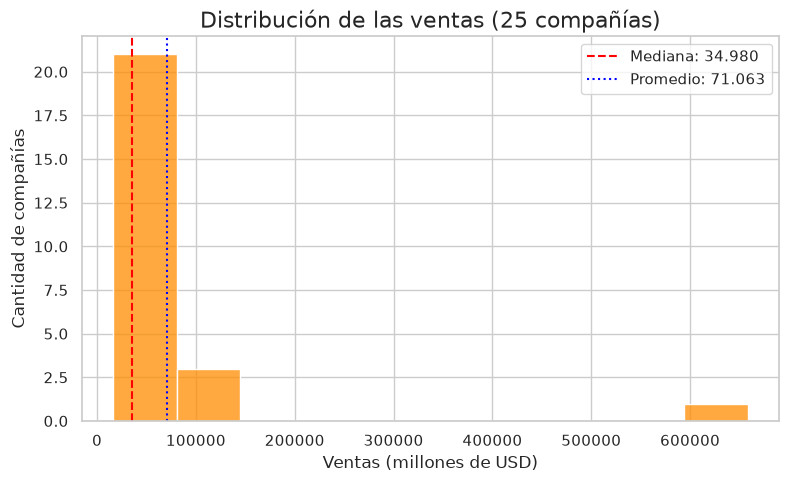

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=datos, x="Sales", bins=10, color=COLOR, ax=ax)
ax.axvline(mediana_ventas, color="red", linestyle="--", label=f"Mediana: {miles(mediana_ventas)}")
ax.axvline(promedio_ventas, color="blue", linestyle=":", label=f"Promedio: {miles(promedio_ventas)}")
ax.set_title("Distribución de las ventas (25 compañías)", size=16)
ax.set_xlabel("Ventas (millones de USD)")
ax.set_ylabel("Cantidad de compañías")
ax.legend()
guardar("03_distribucion_ventas", fig)
plt.show()

### 3. ¿Cuántas tiendas tiene la mayoría de las compañías?

**Respuesta:** la **mediana es de 1.828 tiendas**. De las 23 compañías con dato de tiendas,
**13 (más de la mitad) tienen menos de 2.000 tiendas**. Se usa de nuevo la mediana para reducir el
efecto de los valores extremos (Dollar Tree y Dollar General superan las 13.000).

Amazon y Apple incl. Online no tienen dato de tiendas, por eso quedan fuera de este cálculo.

In [ ]:
con_tiendas = datos.dropna(subset=["Stores"])  # Amazon y Apple no informan tiendas

mediana_tiendas = con_tiendas["Stores"].median()
menos_de_2000 = int((con_tiendas["Stores"] < 2000).sum())

print(f"Compañías con dato de tiendas: {len(con_tiendas)}")
print(f"Mediana de tiendas: {miles(mediana_tiendas)}")
print(f"Compañías con menos de 2.000 tiendas: {menos_de_2000}")

con_tiendas.sort_values("Stores")[["Company", "Stores"]].head(8)

Compañías con dato de tiendas: 23
Mediana de tiendas: 1.828
Compañías con menos de 2.000 tiendas: 13


,Company,Stores
24,Meijer,231.0
21,HEB,323.0
2,Costco,495.0
10,Sam's Club,655.0
15,Ahold,794.0
16,Macy's,889.0
22,Kohl's,1169.0
23,Delhaize,1280.0


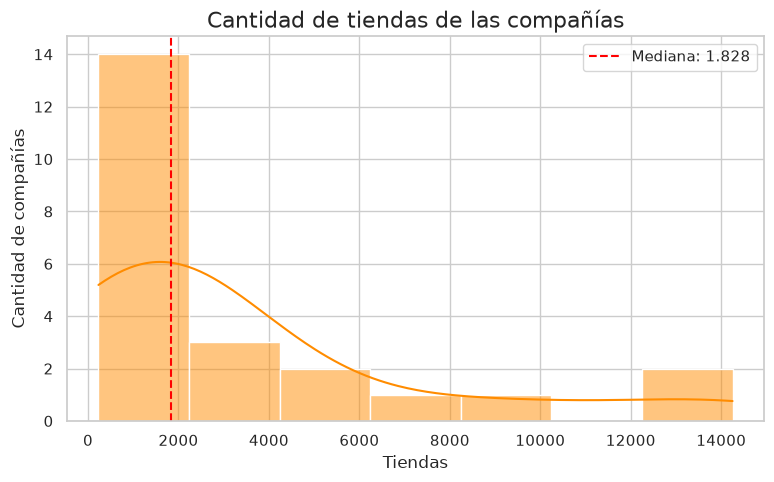

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=con_tiendas, x="Stores", bins=7, kde=True, color=COLOR, ax=ax)
ax.axvline(mediana_tiendas, color="red", linestyle="--", label=f"Mediana: {miles(mediana_tiendas)}")
ax.set_title("Cantidad de tiendas de las compañías", size=16)
ax.set_xlabel("Tiendas")
ax.set_ylabel("Cantidad de compañías")
ax.legend()
guardar("04_distribucion_tiendas", fig)
plt.show()

### 4. ¿La cantidad de tiendas está relacionada con la cantidad de ventas?

**Respuesta:** la relación es **muy débil o nula**. La correlación de Pearson entre ventas y
tiendas es de **0,06** (casi nula) y la de Spearman, que es menos sensible a valores extremos
porque trabaja con el orden de los datos, es de **0,30** (débil). Tener más tiendas no garantiza
más ventas: Dollar Tree (14.250 tiendas), Dollar General (13.350) y CVS incl. Target (9.813)
tienen muchísimas tiendas, pero venden menos que Kroger (3.931 tiendas) o Walmart US (4.574).

In [ ]:
datos.corr(numeric_only=True).round(2)

,Sales,Stores,Sales/Avg. Store,Store Count Growth
Sales,1.00,0.06,0.22,-0.08
Stores,0.06,1.00,-0.45,0.47
Sales/Avg. Store,0.22,-0.45,1.00,-0.06
Store Count Growth,-0.08,0.47,-0.06,1.00


In [ ]:
pearson = con_tiendas["Sales"].corr(con_tiendas["Stores"])
spearman = con_tiendas["Sales"].rank().corr(con_tiendas["Stores"].rank())  # Pearson sobre los rankings

print(f"Correlación de Pearson (ventas vs. tiendas): {pearson:.2f}")
print(f"Correlación de Spearman (ventas vs. tiendas): {spearman:.2f}")

Correlación de Pearson (ventas vs. tiendas): 0.06
Correlación de Spearman (ventas vs. tiendas): 0.30


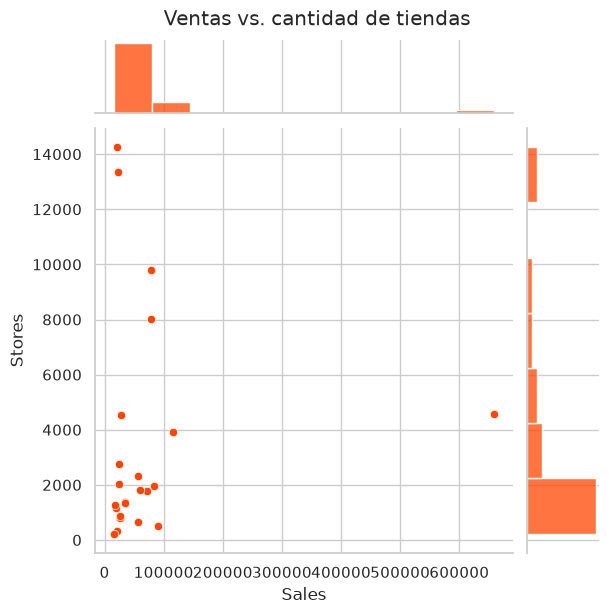

In [ ]:
g = sns.jointplot(data=con_tiendas, x="Sales", y="Stores", color="orangered")
g.figure.suptitle("Ventas vs. cantidad de tiendas", y=1.02)
guardar("05_ventas_vs_tiendas", g.figure)
plt.show()

### 5. ¿Cuál es el rango que existe entre las ventas?

**Respuesta:** el rango es de **USD 641.527 millones**: la diferencia entre la compañía que más
vende (Walmart US, 658.119) y la que menos (Meijer, 16.592).

In [ ]:
venta_max = datos["Sales"].max()
venta_min = datos["Sales"].min()
rango = venta_max - venta_min

print(f"Máximo: {miles(venta_max)} | Mínimo: {miles(venta_min)} | Rango: {miles(rango)}")

Máximo: 658.119 | Mínimo: 16.592 | Rango: 641.527


### 6. ¿Cuáles son las 5 empresas que más tiendas físicas tienen? ¿Cuáles de ellas están también entre las 5 que más vendieron?

**Respuesta:** las 5 con más tiendas son **Dollar Tree** (14.250), **Dollar General** (13.350),
**CVS incl. Target** (9.813), **Walgreen Boots** (8.002) y **Walmart US** (4.574).

Dos de ellas también están entre las 5 que más vendieron: **Walmart US** (1.ª en ventas) y
**Walgreen Boots** (5.ª en ventas).

In [ ]:
top5_tiendas = con_tiendas.nlargest(5, "Stores")[["Company", "Stores", "Sales"]]
top5_ventas = datos.nlargest(5, "Sales")[["Company", "Sales", "Stores"]]

print("Top 5 por cantidad de tiendas:")
display(top5_tiendas)
print("Top 5 por ventas:")
display(top5_ventas)

en_ambos = sorted(set(top5_tiendas["Company"]) & set(top5_ventas["Company"]))
print("En ambos rankings:", en_ambos)

Top 5 por cantidad de tiendas:


,Company,Stores,Sales
20,Dollar Tree,14250.0,21464
19,Dollar General,13350.0,22234
5,CVS incl. Target,9813.0,77792
4,Walgreen Boots,8002.0,78924
0,Walmart US,4574.0,658119


Top 5 por ventas:


,Company,Sales,Stores
0,Walmart US,658119,4574.0
1,Kroger,115037,3931.0
2,Costco,90048,495.0
3,Home Depot,83976,1965.0
4,Walgreen Boots,78924,8002.0


En ambos rankings: ['Walgreen Boots', 'Walmart US']


## II. Preguntas opcionales

### 7. ¿Qué categoría de compañía generó más ventas?

**Respuesta:** **Supercenters**, con **USD 745.919 millones**, seguida de **Grocery**
(297.164) y **Drug Stores** (184.202).

> Limpieza previa: en el dataset aparecen `Warehouse Club` y `Warehouse Clubs` como si fueran
> categorías distintas; se unifican en una sola. Apple incl. Online no tiene categoría y no
> entra en este cálculo.

In [ ]:
datos_cat = datos.assign(Category=datos["Category"].replace({"Warehouse Clubs": "Warehouse Club"}))

ventas_categoria = (
    datos_cat.groupby("Category")["Sales"].sum().sort_values(ascending=False).reset_index()
)

ventas_categoria.style.background_gradient(
    cmap=sns.light_palette("orange", as_cmap=True), subset=["Sales"]
).format({"Sales": "{:,.0f}"})

,Category,Sales
0,Supercenters,"745,919"
1,Grocery,"297,164"
2,Drug Stores,"184,202"
3,Warehouse Club,"146,876"
4,Home Improvement,"144,287"
5,Electronic/Mail Order,"71,687"
6,Department Stores,"45,088"
7,Dollar Stores,"43,698"
8,Electronics,"34,980"
9,Apparel,"25,012"


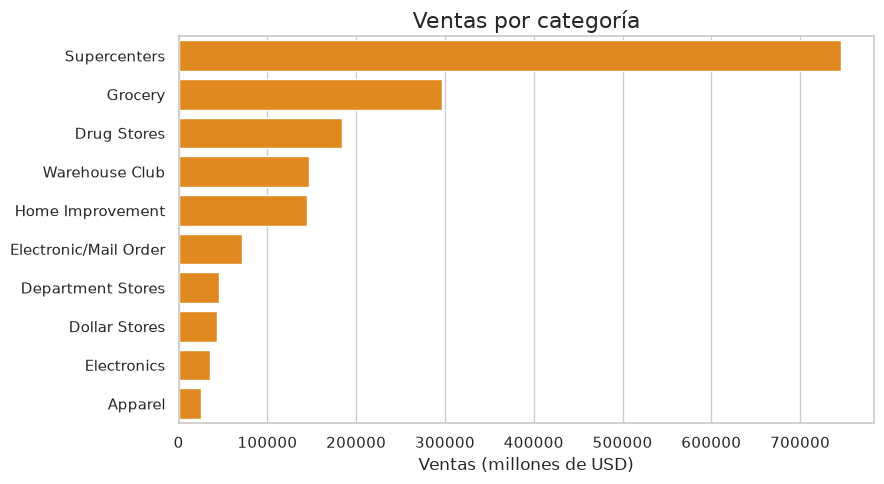

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(data=ventas_categoria, x="Sales", y="Category", color=COLOR)
plt.title("Ventas por categoría", size=16)
plt.xlabel("Ventas (millones de USD)")
plt.ylabel("")
plt.tight_layout()
guardar("07_ventas_por_categoria")
plt.show()

### 8. ¿Cuál es la compañía que, en relación con su cantidad de tiendas físicas, genera más ventas?

**Respuesta:** **Costco**, con **USD 187,8 millones de ventas por tienda**. Lo siguen Sam's Club
(87,3) y Meijer (74,7).

In [ ]:
ventas_tienda = (
    datos.dropna(subset=["Sales/Avg. Store"])
    .sort_values("Sales/Avg. Store", ascending=False)[["Company", "Sales/Avg. Store"]]
)
ventas_tienda.head(5)

,Company,Sales/Avg. Store
2,Costco,187.795620
10,Sam's Club,87.293395
24,Meijer,74.738739
21,HEB,66.825000
0,Walmart US,65.649725


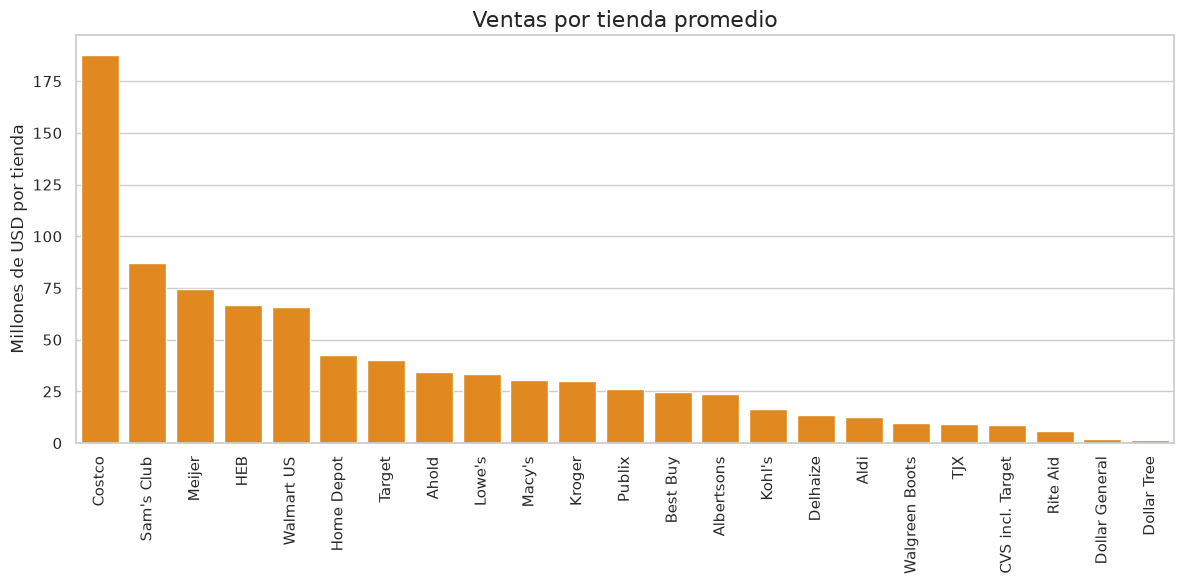

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=ventas_tienda, x="Company", y="Sales/Avg. Store", color=COLOR)
plt.title("Ventas por tienda promedio", size=16)
plt.xlabel("")
plt.ylabel("Millones de USD por tienda")
plt.xticks(rotation=90)
plt.tight_layout()
guardar("08_ventas_por_tienda")
plt.show()

### 9. ¿Cuáles compañías venden de forma exclusivamente online? ¿Sus ventas destacan sobre las que también tienen tiendas físicas?

El dataset no indica qué compañías son online. El criterio usado es **no tener dato de tiendas
físicas**: quedan **Amazon** y **Apple incl. Online**.

**Respuesta:** sí destacan. Amazon es la 7.ª en ventas (71.687) y Apple la 12.ª (37.664). La
mediana de ventas de las dos es de **54.676**, contra **34.408** de la mediana de las 23
compañías con tiendas físicas.

> Precauciones: son solo 2 compañías y el criterio es una suposición. Además, "Apple incl.
> Online" sugiere que su cifra incluye también tiendas, por lo que no es estrictamente
> "solo online".

In [ ]:
datos_rank = datos.assign(Ranking_ventas=datos["Sales"].rank(ascending=False).astype(int))
sin_dato_tiendas = datos_rank[datos_rank["Stores"].isna()]
sin_dato_tiendas[["Company", "Sales", "Category", "Ranking_ventas"]]

,Company,Sales,Category,Ranking_ventas
6,Amazon,71687,Electronic/Mail Order,7
11,Apple incl. Online,37664,NaN,12


In [ ]:
mediana_online = sin_dato_tiendas["Sales"].median()
mediana_fisicas = con_tiendas["Sales"].median()

print(f"Mediana de ventas, compañías sin dato de tiendas (online): {miles(mediana_online)}")
print(f"Mediana de ventas, compañías con tiendas físicas: {miles(mediana_fisicas)}")

Mediana de ventas, compañías sin dato de tiendas (online): 54.676
Mediana de ventas, compañías con tiendas físicas: 34.408


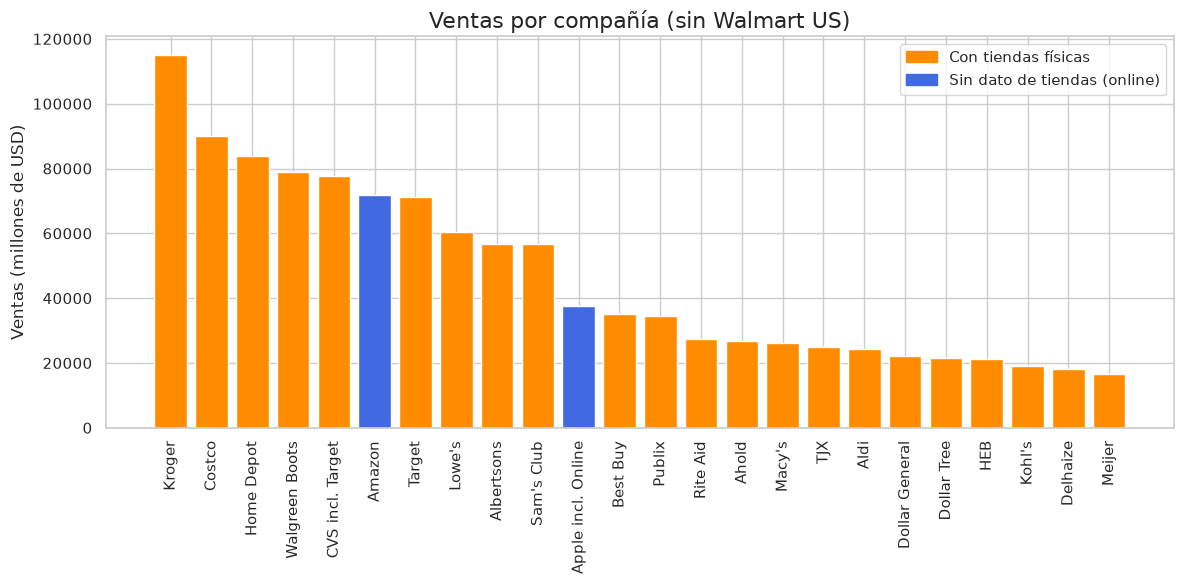

In [ ]:
orden = datos[datos["Company"] != "Walmart US"].sort_values("Sales", ascending=False)
colores = np.where(orden["Stores"].isna(), "royalblue", COLOR)

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(orden["Company"], orden["Sales"], color=colores)
ax.set_title("Ventas por compañía (sin Walmart US)", size=16)
ax.set_ylabel("Ventas (millones de USD)")
ax.tick_params(axis="x", rotation=90)
ax.legend(
    handles=[
        Patch(color=COLOR, label="Con tiendas físicas"),
        Patch(color="royalblue", label="Sin dato de tiendas (online)"),
    ]
)
fig.tight_layout()
guardar("09_online_vs_fisicas", fig)
plt.show()

## III. Preguntas propias

### 10. ¿Cuáles son los outliers?

Se usa la regla del **rango intercuartil (IQR)**: es outlier todo valor que quede por fuera de
`[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]`, donde Q1 es el cuartil 25 %, Q3 el 75 % e
IQR = Q3 − Q1 (el rango del 50 % central de los datos).

**Respuesta:**

- **Ventas:** el único outlier es **Walmart US** (658.119, muy por encima del límite superior de 142.615).
- **Cantidad de tiendas:** son outliers **Dollar Tree** (14.250), **Dollar General** (13.350) y
  **CVS incl. Target** (9.813), por encima del límite superior de 9.062.

In [ ]:
def limites_iqr(serie, factor=1.5):
    """Devuelve Q1, Q3, IQR y los límites inferior y superior de la regla del IQR."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - factor * iqr, q3 + factor * iqr


for columna in ["Sales", "Stores"]:
    q1, q3, iqr, inferior, superior = limites_iqr(datos[columna].dropna())
    atipicos = datos[(datos[columna] < inferior) | (datos[columna] > superior)]
    print(f"--- {columna} ---")
    print(f"Q1 = {miles(q1)} | Q3 = {miles(q3)} | IQR = {miles(iqr)}")
    print(f"Límites: [{miles(inferior, 1)} ; {miles(superior, 1)}]")
    print("Outliers:", atipicos["Company"].tolist(), "\n")

print(f"Desviación estándar de las ventas: {miles(datos['Sales'].std(), 1)}")

--- Sales ---
Q1 = 24.402 | Q3 = 71.687 | IQR = 47.285
Límites: [-46.525,5 ; 142.614,5]
Outliers: ['Walmart US'] 

--- Stores ---
Q1 = 1.029 | Q3 = 4.242 | IQR = 3.213
Límites: [-3.790,5 ; 9.061,5]
Outliers: ['CVS incl. Target', 'Dollar General', 'Dollar Tree'] 

Desviación estándar de las ventas: 125.405,7


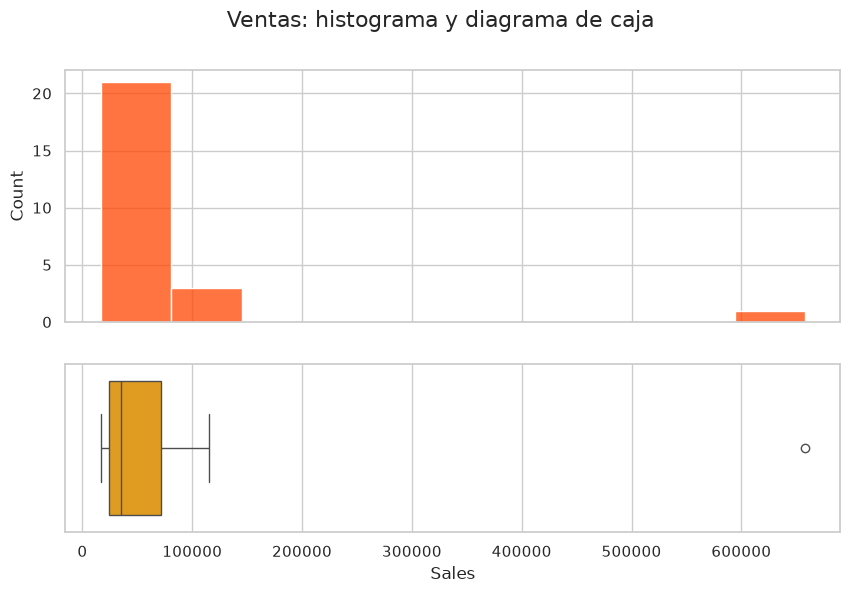

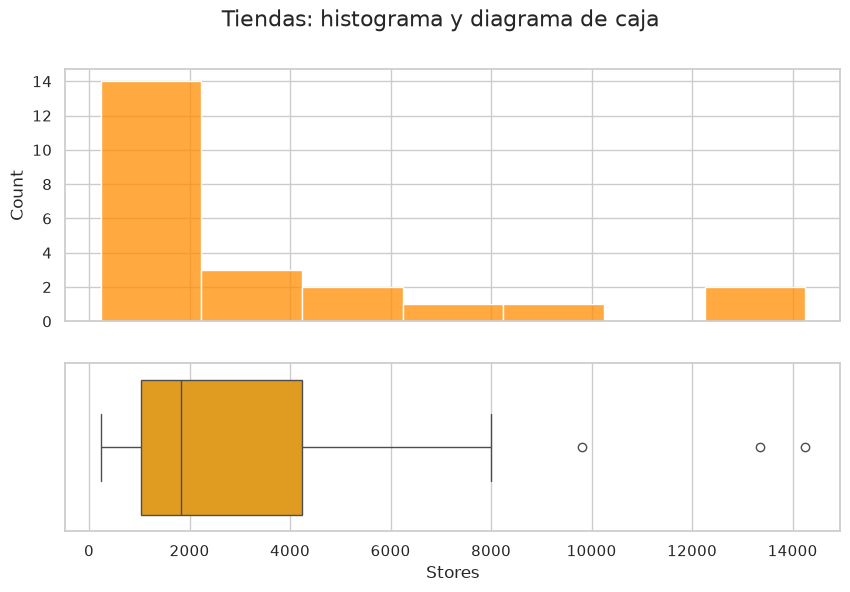

In [ ]:
def distribucion(columna, titulo, nombre, color):
    """Histograma y diagrama de caja de una columna, compartiendo el eje x."""
    fig, (ax_hist, ax_box) = plt.subplots(
        2, sharex=True, figsize=(10, 6), gridspec_kw={"height_ratios": (0.6, 0.4)}
    )
    sns.histplot(data=datos, x=columna, ax=ax_hist, color=color)
    sns.boxplot(data=datos, x=columna, ax=ax_box, color="orange")
    ax_hist.set(xlabel="")
    fig.suptitle(titulo, size=16)
    guardar(nombre, fig)
    plt.show()


distribucion("Sales", "Ventas: histograma y diagrama de caja", "10_outliers_ventas", "orangered")
distribucion("Stores", "Tiendas: histograma y diagrama de caja", "10_outliers_tiendas", "darkorange")

### 11. ¿Cuál es la empresa que tuvo menores ventas?

**Respuesta:** **Meijer**, con **USD 16.592 millones** (231 tiendas, categoría Supercenters).

In [ ]:
# idxmin() devuelve la posición de la fila donde Sales es mínimo.
datos.loc[datos["Sales"].idxmin(), ["Company", "Sales", "Stores", "Category"]]

Company           Meijer
Sales              16592
Stores             231.0
Category    Supercenters
Name: 24, dtype: object

## Conclusiones

| # | Pregunta | Resultado |
|---|---|---|
| 1 | Promedio de ventas sin Walmart US | USD 46.602 millones |
| 2 | Ventas de la mayoría (mediana) | USD 34.980 millones |
| 3 | Tiendas de la mayoría (mediana) | 1.828 tiendas (13 de 23 compañías con menos de 2.000) |
| 4 | ¿Más tiendas = más ventas? | No de forma clara: Pearson 0,06 / Spearman 0,30 |
| 5 | Rango de ventas | USD 641.527 millones |
| 6 | Top 5 tiendas ∩ top 5 ventas | Walmart US y Walgreen Boots |
| 7 | Categoría con más ventas | Supercenters (745.919) |
| 8 | Más ventas por tienda | Costco (187,8) |
| 9 | Compañías sin tiendas informadas | Amazon y Apple: ventas por encima de la mediana |
| 10 | Outliers | Ventas: Walmart US · Tiendas: Dollar Tree, Dollar General y CVS incl. Target |
| 11 | Menores ventas | Meijer (16.592) |

**Lectura general:** el mercado está dominado por Walmart US, que distorsiona el promedio y por eso
la mediana es la medida más representativa. La cantidad de tiendas no explica por sí sola el
volumen de ventas: importan también el tipo de negocio y las ventas por tienda (por ejemplo,
Costco con pocas tiendas, o las cadenas "dollar" con muchísimas tiendas pero ventas bajas).